# Experiment B1 — fixed-$D$ batch-size sweep with fixed momentum

This notebook fixes the total data budget at
\[
D=2^{20},\qquad K=\lfloor D/B\rfloor,
\]
and sweeps powers-of-two batch sizes. HB and Nesterov use the nominal momentum inherited from the original $D$-sweep schedule at this fixed $D$:
\[
1-\rho=C_\rho D^{-1/(2s+2)},\qquad \eta=0.05.
\]
SGD keeps $\rho=0$. The vertical lines mark the predicted useful-batch exponents from `exp.md`.

The experiment uses a single configurable source parameter `S_VALUE`. The code uses exact chunked minibatch gradients so large batches do not require materializing a full `(B, DIM)` matrix at once.


In [18]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

BETA = 2
SIGMA = 1
DIM = 4096
D_FIXED = 2 ** 15
ETA_FIXED = 0.1
C_RHO = 1.0
CHUNK = 2048
N_SEEDS = 5
LOAD_CACHE = True
SAVE_CACHE = True

# Single source-smoothness parameter for this experiment.
# Change only this value if you want to rerun the sweep for a different s.
S_VALUE = 1
S_CASES = [
    {'key': f's_{S_VALUE:g}'.replace('.', '_'), 'title': rf'$s={S_VALUE:.2f}$', 's': S_VALUE},
]

ALGOS = {
    'HB': 'hb',
    'Nesterov': 'nag',
    'SGD': 'sgd',
}

B_EXPONENTS = list(range(3, 15))
B_LIST = [2 ** e for e in B_EXPONENTS if 2 ** e <= D_FIXED]
RESULT_DIR = Path('results')
RESULT_DIR.mkdir(exist_ok=True)

print(f'beta={BETA}, sigma={SIGMA}, dim={DIM}, D=2^{int(np.log2(D_FIXED))}, seeds={N_SEEDS}')
print(f'batch grid: 2^{B_EXPONENTS[0]} ... 2^{B_EXPONENTS[-1]} ({len(B_LIST)} values)')


beta=2, sigma=1, dim=4096, D=2^15, seeds=5
batch grid: 2^3 ... 2^14 (12 values)


In [19]:
def build_problem(dim=DIM, beta=BETA, s=1.0):
    """Return (lam, theta_star) for the diagonal linear-regression problem."""
    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    var_star = j ** (-(1.0 + (s - 1.0) * beta))
    theta_star = np.sqrt(var_star)
    return lam, theta_star


def excess_loss(delta, lam):
    """Exact population excess loss E = 1/2 * sum_j lam_j * delta_j^2."""
    return 0.5 * np.sum(lam * delta * delta)


def grad_delta_chunked(delta, B, lam, sigma=SIGMA, rng=None, chunk=CHUNK):
    """Exact stochastic minibatch gradient without materializing a full (B, DIM) batch."""
    rng = rng or np.random.default_rng()
    d = lam.shape[0]
    sqrt_lam = np.sqrt(lam)
    grad = np.zeros(d, dtype=np.float64)
    remaining = int(B)
    while remaining > 0:
        b = min(chunk, remaining)
        X = rng.standard_normal((b, d)) * sqrt_lam
        eps = rng.standard_normal(b) * sigma
        resid = X @ delta - eps
        grad += X.T @ resid
        remaining -= b
    return grad / B


def run_optimizer(algo, B, K, eta, rho, lam, theta_star, sigma=SIGMA, rng=None, record_curve=False):
    """Run one of {'hb','nag','sgd'} for K steps of batch size B."""
    rng = rng or np.random.default_rng()
    if algo == 'sgd':
        rho = 0.0
    delta = -theta_star.copy()
    delta_prev = delta.copy()
    curve = [excess_loss(delta, lam)] if record_curve else None
    for _ in range(int(K)):
        momentum = delta - delta_prev
        eval_delta = delta + rho * momentum if algo == 'nag' else delta
        g = grad_delta_chunked(eval_delta, B, lam, sigma=sigma, rng=rng)
        delta_new = delta - eta * g + rho * momentum
        delta_prev, delta = delta, delta_new
        if record_curve:
            curve.append(excess_loss(delta, lam))
    final_E = excess_loss(delta, lam)
    return final_E, np.array(curve) if record_curve else None


def alpha_hb(s, beta=BETA):
    return min(s, 2.0 - 1.0 / beta)


def predicted_batch_exponents(s, beta=BETA):
    """Theory-guided useful-batch exponents a=log(B)/log(D)."""
    return {
        'SGD': s / (s + 1.0),
        'HB': min((2.0 * s + 1.0) / (2.0 * s + 2.0), (s + alpha_hb(s, beta)) / (s + 1.0)),
        'Nesterov': (2.0 * s + 1.0) / (2.0 * s + 2.0),
    }


def clipped_rho(one_minus_rho):
    one_minus_rho = float(np.clip(one_minus_rho, 1e-5, 1.0))
    return float(np.clip(1.0 - one_minus_rho, 0.0, 0.99999))


def fixed_D_nominal_rho(s, D=D_FIXED, c_rho=C_RHO):
    b = 1.0 / (2.0 * s + 2.0)
    return clipped_rho(c_rho * D ** (-b))


def cache_key(prefix):
    s_tag = f's{S_VALUE:g}'.replace('.', '_')
    return RESULT_DIR / f'{prefix}_{s_tag}_dim{DIM}_D{D_FIXED}_beta{BETA}_sigma{SIGMA}_seeds{N_SEEDS}.npz'


## Run the fixed-momentum sweep

For small `B`, `K=D/B` is very large. If you are debugging, reduce `DIM`, `N_SEEDS`, or narrow `B_EXPONENTS`; for the paper run, keep `D_FIXED=2**20` and the full grid.


In [20]:
cache_path = cache_key('batch_fixed_momentum')

if LOAD_CACHE and cache_path.exists():
    BATCH_RESULTS = np.load(cache_path, allow_pickle=True)['results'].item()
    print(f'loaded cached results from {cache_path}')
else:
    BATCH_RESULTS = {}
    for case in S_CASES:
        key, s = case['key'], case['s']
        lam, theta_star = build_problem(s=s)
        rho_momentum = fixed_D_nominal_rho(s)
        print(f"=== {case['title']}  fixed rho(HB/NAG)={rho_momentum:.6f} ===")

        payload = {'B': B_LIST, 'rho_momentum': rho_momentum}
        for name in ALGOS:
            payload[name] = {'mean': [], 'std': [], 'all': []}

        for B in B_LIST:
            K = max(1, D_FIXED // B)
            print(f'B=2^{int(np.log2(B)):<2d} ({B:6d}), K={K:7d}')
            for name, algo in ALGOS.items():
                rho = 0.0 if algo == 'sgd' else rho_momentum
                vals = []
                for seed in range(N_SEEDS):
                    rng = np.random.default_rng(1_000_000 + 100_000 * seed + 1000 * int(100 * s) + B)
                    final_E, _ = run_optimizer(algo, B, K, ETA_FIXED, rho, lam, theta_star, rng=rng)
                    vals.append(final_E)
                vals = np.array(vals)
                payload[name]['mean'].append(float(vals.mean()))
                payload[name]['std'].append(float(vals.std()))
                payload[name]['all'].append(vals.tolist())
                print(f'  {name:9s} E_K={vals.mean():.3e} +/- {vals.std():.1e}  rho={rho:.5f}')
        BATCH_RESULTS[key] = payload
        print()

    if SAVE_CACHE:
        np.savez_compressed(cache_path, results=BATCH_RESULTS)
        print(f'saved results to {cache_path}')


=== $s=1.00$  fixed rho(HB/NAG)=0.925675 ===
B=2^3  (     8), K=   4096
  HB        E_K=4.638e-02 +/- 2.9e-02  rho=0.92567
  Nesterov  E_K=2.976e-02 +/- 7.2e-03  rho=0.92567
  SGD       E_K=4.588e-03 +/- 2.7e-03  rho=0.00000
B=2^4  (    16), K=   2048
  HB        E_K=3.218e-02 +/- 1.9e-02  rho=0.92567
  Nesterov  E_K=1.629e-02 +/- 6.5e-03  rho=0.92567
  SGD       E_K=2.664e-03 +/- 1.3e-03  rho=0.00000
B=2^5  (    32), K=   1024
  HB        E_K=2.369e-02 +/- 1.7e-02  rho=0.92567
  Nesterov  E_K=1.661e-02 +/- 1.1e-02  rho=0.92567
  SGD       E_K=5.375e-03 +/- 3.8e-03  rho=0.00000
B=2^6  (    64), K=    512
  HB        E_K=1.635e-02 +/- 1.3e-02  rho=0.92567
  Nesterov  E_K=7.939e-03 +/- 4.0e-03  rho=0.92567
  SGD       E_K=3.151e-03 +/- 3.9e-04  rho=0.00000
B=2^7  (   128), K=    256
  HB        E_K=6.348e-03 +/- 2.9e-03  rho=0.92567
  Nesterov  E_K=3.398e-03 +/- 1.1e-03  rho=0.92567
  SGD       E_K=5.100e-03 +/- 2.6e-04  rho=0.00000
B=2^8  (   256), K=    128
  HB        E_K=2.091e-03 +/

## Plot: final excess loss versus batch size


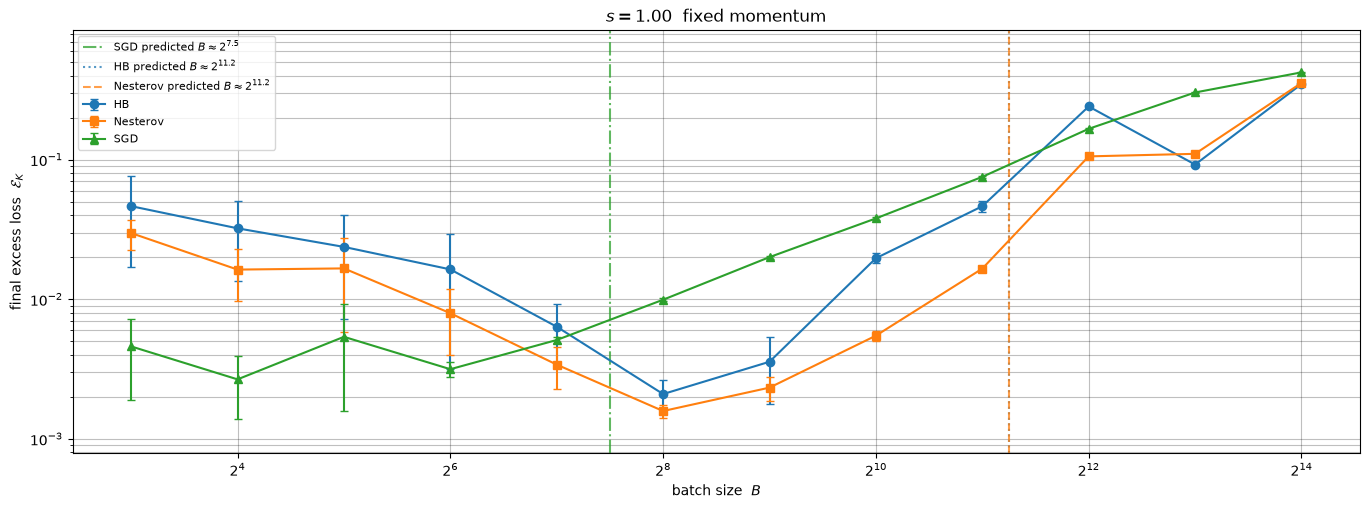

In [21]:
def plot_batch_sweep(results, title_suffix):
    colors = {'HB': 'tab:blue', 'Nesterov': 'tab:orange', 'SGD': 'tab:green'}
    markers = {'HB': 'o', 'Nesterov': 's', 'SGD': '^'}
    linestyles = {'HB': ':', 'Nesterov': '--', 'SGD': '-.'}

    fig, axes = plt.subplots(1, len(S_CASES), figsize=(13.8, 5.2), sharey=False)
    if len(S_CASES) == 1:
        axes = [axes]

    for ax, case in zip(axes, S_CASES):
        payload = results[case['key']]
        B_arr = np.array(payload['B'], dtype=float)
        pred = predicted_batch_exponents(case['s'])

        for name in ALGOS:
            mean = np.array(payload[name]['mean'])
            std = np.array(payload[name]['std'])
            ax.errorbar(B_arr, mean, yerr=std, marker=markers[name], capsize=3,
                        color=colors[name], label=name)

        ymax = max(np.nanmax(payload[name]['mean']) for name in ALGOS)
        ymin = min(np.nanmin(payload[name]['mean']) for name in ALGOS)
        for name, a_pred in pred.items():
            B_pred = D_FIXED ** a_pred
            if B_arr[0] <= B_pred <= B_arr[-1]:
                ax.axvline(B_pred, color=colors[name], linestyle=linestyles[name], alpha=0.75,
                           label=rf'{name} predicted $B\approx 2^{{{np.log2(B_pred):.1f}}}$')

        ax.set_xscale('log', base=2)
        ax.set_yscale('log')
        ax.set_xlabel('batch size  $B$')
        ax.set_ylabel(r'final excess loss  $\mathcal{E}_K$')
        ax.set_title(f"{case['title']}  {title_suffix}")
        ax.grid(True, which='both', color=(0, 0, 0, 0.25))
        ax.legend(fontsize=8)
        ax.set_ylim(max(ymin * 0.5, 1e-12), ymax * 2.0)

    plt.tight_layout()
    plt.show()

plot_batch_sweep(BATCH_RESULTS, 'fixed momentum')


## Notes

Expected behavior is an elbow or U-shape: small batches have a larger stochastic noise floor, while very large batches have too few optimization steps. Momentum should move the useful-batch region to the right compared with SGD when the constants are well tuned.
